# Avance 2. Ingeniería de características
## Traductor de Lengua de Señas Mexicana — Equipo 47

**Integrantes:** Marco Antonio Arellano, Miguel Octavio Ramírez y Hugo Enrique Navarro Villeda.

Esta libreta transforma un video de una seña dinámica en tres productos:

1. Una secuencia temporal de landmarks de manos, rostro y postura.
2. Archivos CSV y NPZ que conservan los datos crudos, la detección y las versiones normalizadas.
3. Una fila de características geométricas y temporales por video, lista para integrarse al dataset del proyecto.

La unidad de observación es **un video completo**, no una mano aislada ni un frame independiente. De esta forma se conservan simultáneamente ambas manos y el orden temporal del gesto.

## 1. Preparación del entorno

La instalación se realiza sin desinstalar paquetes del entorno. Si Google Colab solicita reiniciar la sesión después de instalar MediaPipe, se reinicia una sola vez y se vuelve a ejecutar la libreta desde el inicio.

In [29]:
%pip -q install "mediapipe==0.10.35" "scikit-learn>=1.3" "pandas>=2.0" joblib

In [30]:
from pathlib import Path
import json
import math
import warnings

import cv2
import joblib
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np
import pandas as pd
import seaborn as sns

from IPython.display import Video, display
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.preprocessing import PowerTransformer, StandardScaler

warnings.filterwarnings("ignore", category=RuntimeWarning)
sns.set_theme(style="whitegrid")

print("MediaPipe:", mp.__version__)
print("OpenCV:", cv2.__version__)

MediaPipe: 0.10.35
OpenCV: 5.0.0


## 2. Selección del video

En Google Colab se abre el panel **Archivos** (icono de carpeta), se carga el video y se cambia únicamente `VIDEO_FILENAME`.

Para que la libreta obtenga automáticamente la etiqueta y los metadatos, los archivos deben seguir el formato **`Seña_Participante_Repetición.mp4`**, por ejemplo: `Necesitar_Hugo_01.mp4`. Si una seña contiene varias palabras, se usan guiones: `Buenos-dias_Hugo_01.mp4`.

La interfaz actual de MediaPipe Holistic devuelve directamente los landmarks de la mano izquierda y derecha. La vista previa anotada permite confirmar visualmente que el encuadre y la detección sean correctos.

In [31]:
# Cambia aquí el nombre del video.

VIDEO_FILENAME = "Necesitarcv _Hugo_01.mp4"

# Parámetros del procesamiento.
SKIP = 1
MAX_INTERPOLATION_GAP = 5
CREATE_ANNOTATED_VIDEO = True

BASE_DIR = Path("/content") if Path("/content").exists() else Path.cwd()
VIDEO_PATH = BASE_DIR / VIDEO_FILENAME
OUTPUT_DIR = BASE_DIR / "output_avance2"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

HOLISTIC_MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/holistic_landmarker/"
    "holistic_landmarker/float16/1/holistic_landmarker.task"
)
HOLISTIC_MODEL_PATH = BASE_DIR / "holistic_landmarker.task"

if not HOLISTIC_MODEL_PATH.exists():
    import urllib.request
    print("Descargando el modelo Holistic Landmarker...")
    urllib.request.urlretrieve(HOLISTIC_MODEL_URL, HOLISTIC_MODEL_PATH)

filename_parts = Path(VIDEO_FILENAME).stem.rsplit("_", 2)
if len(filename_parts) != 3 or not all(filename_parts):
    raise ValueError(
        "El nombre debe seguir el formato Seña_Participante_Repetición.mp4; "
        "por ejemplo, Necesitar_Hugo_01.mp4"
    )
SIGN_LABEL = filename_parts[0].replace("-", " ")
PARTICIPANT_ID = filename_parts[1].replace("-", " ")
REPETITION_ID = filename_parts[2]
VIDEO_ID = Path(VIDEO_FILENAME).stem
NPZ_PATH = OUTPUT_DIR / f"{VIDEO_ID}_secuencia.npz"
HANDS_CSV_PATH = OUTPUT_DIR / f"{VIDEO_ID}_landmarks_manos.csv"
FACE_CSV_PATH = OUTPUT_DIR / f"{VIDEO_ID}_landmarks_rostro.csv"
POSE_CSV_PATH = OUTPUT_DIR / f"{VIDEO_ID}_landmarks_postura.csv"
FEATURES_CSV_PATH = OUTPUT_DIR / f"{VIDEO_ID}_caracteristicas.csv"
MASTER_FEATURES_PATH = OUTPUT_DIR / "dataset_caracteristicas.csv"
ANNOTATED_VIDEO_PATH = OUTPUT_DIR / f"{VIDEO_ID}_anotado.mp4"

if not VIDEO_PATH.exists():
    videos_disponibles = sorted(
        p.name for pattern in ("*.mp4", "*.mov", "*.avi", "*.mkv")
        for p in BASE_DIR.glob(pattern)
    )
    raise FileNotFoundError(
        f"No se encontró {VIDEO_PATH}. Sube el archivo al panel Archivos de Colab "
        f"y verifica VIDEO_FILENAME. Videos disponibles: {videos_disponibles}"
    )

print("Video:", VIDEO_PATH)
print("Identificador:", VIDEO_ID)
print("Resultados:", OUTPUT_DIR)

Video: /content/Necesitar_Hugo_01.mp4
Identificador: Necesitar_Hugo_01
Resultados: /content/output_avance2


## 3. Extracción temporal de landmarks

Se almacenan:

- **Manos:** 21 landmarks por mano en el orden fijo `[izquierda, derecha]`, con forma `(frames, 2, 21, 3)`.
- **Rostro:** un subconjunto de puntos de ojos, cejas y boca relacionado con componentes no manuales de la LSM.
- **Postura:** 33 landmarks corporales para representar brazos, hombros y posición relativa de las manos.

Si una parte no se detecta en un frame, sus coordenadas se conservan como `NaN`. No se reemplazan por cero, porque cero es una coordenada válida y confundiría ausencia con posición.

In [32]:
# Landmarks usados del rostro.
FACE_INDICES = np.array([
    1, 33, 133, 159, 145, 263, 362, 386, 374,
    61, 291, 13, 14, 78, 308,
    70, 63, 105, 66, 107, 336, 296, 334, 293, 300
], dtype=int)

HAND_NAMES = ("left", "right")
HAND_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3), (3, 4),
    (0, 5), (5, 6), (6, 7), (7, 8),
    (5, 9), (9, 10), (10, 11), (11, 12),
    (9, 13), (13, 14), (14, 15), (15, 16),
    (13, 17), (17, 18), (18, 19), (19, 20), (0, 17),
]
POSE_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3), (3, 7),
    (0, 4), (4, 5), (5, 6), (6, 8), (9, 10),
    (11, 12), (11, 13), (13, 15), (15, 17), (17, 19),
    (19, 15), (15, 21), (12, 14), (14, 16), (16, 18),
    (18, 20), (20, 16), (16, 22), (11, 23), (12, 24),
    (23, 24), (23, 25), (25, 27), (27, 29), (29, 31),
    (31, 27), (24, 26), (26, 28), (28, 30), (30, 32), (32, 28),
]


def landmarks_to_array(landmarks, expected_count, include_visibility=False):
    columns = 4 if include_visibility else 3
    result = np.full((expected_count, columns), np.nan, dtype=np.float32)
    if not landmarks:
        return result
    count = min(expected_count, len(landmarks))
    for index in range(count):
        landmark = landmarks[index]
        result[index, :3] = [landmark.x, landmark.y, landmark.z]
        if include_visibility:
            result[index, 3] = getattr(landmark, "visibility", np.nan)
    return result


def draw_landmarks_cv2(image, points, connections, color, radius=2):
    height, width = image.shape[:2]
    pixels = []
    for point in points:
        if np.isfinite(point[:2]).all():
            pixels.append((int(point[0] * width), int(point[1] * height)))
        else:
            pixels.append(None)
    for start, end in connections:
        if start < len(pixels) and end < len(pixels):
            if pixels[start] is not None and pixels[end] is not None:
                cv2.line(image, pixels[start], pixels[end], color, 2)
    for point in pixels:
        if point is not None:
            cv2.circle(image, point, radius, color, -1)


def extract_landmarks_from_video(video_path, annotated_path=None):
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise ValueError(f"OpenCV no pudo abrir el video: {video_path}")

    fps_original = float(cap.get(cv2.CAP_PROP_FPS))
    if not np.isfinite(fps_original) or fps_original <= 0:
        fps_original = 30.0
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps_effective = fps_original / SKIP

    writer = None
    if CREATE_ANNOTATED_VIDEO and annotated_path is not None:
        fourcc = cv2.VideoWriter_fourcc(*"mp4v")
        writer = cv2.VideoWriter(
            str(annotated_path), fourcc, fps_effective, (width, height)
        )

    hands_frames, face_frames, pose_frames = [], [], []
    source_frames, timestamps = [], []
    source_frame = 0

    options = vision.HolisticLandmarkerOptions(
        base_options=mp_python.BaseOptions(
            model_asset_path=str(HOLISTIC_MODEL_PATH)
        ),
        running_mode=vision.RunningMode.VIDEO,
        min_face_detection_confidence=0.50,
        min_face_landmarks_confidence=0.50,
        min_pose_detection_confidence=0.50,
        min_pose_landmarks_confidence=0.50,
        min_hand_landmarks_confidence=0.50,
        output_face_blendshapes=False,
        output_segmentation_mask=False,
    )

    with vision.HolisticLandmarker.create_from_options(options) as holistic_model:
        while True:
            ok, frame = cap.read()
            if not ok:
                break

            if source_frame % SKIP != 0:
                source_frame += 1
                continue

            rgb = np.ascontiguousarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
            timestamp_ms = int(round(source_frame * 1000 / fps_original))
            result = holistic_model.detect_for_video(mp_image, timestamp_ms)

            hands_arr = np.full((2, 21, 3), np.nan, dtype=np.float32)
            hands_arr[0] = landmarks_to_array(result.left_hand_landmarks, 21)
            hands_arr[1] = landmarks_to_array(result.right_hand_landmarks, 21)

            face_arr = np.full((len(FACE_INDICES), 3), np.nan, dtype=np.float32)
            if result.face_landmarks and len(result.face_landmarks) > FACE_INDICES.max():
                face_arr = np.array(
                    [[result.face_landmarks[i].x,
                      result.face_landmarks[i].y,
                      result.face_landmarks[i].z] for i in FACE_INDICES],
                    dtype=np.float32,
                )

            pose_arr = landmarks_to_array(
                result.pose_landmarks, 33, include_visibility=True
            )

            hands_frames.append(hands_arr)
            face_frames.append(face_arr)
            pose_frames.append(pose_arr)
            source_frames.append(source_frame)
            timestamps.append(source_frame / fps_original)

            if writer is not None:
                annotated = frame.copy()
                draw_landmarks_cv2(
                    annotated, hands_arr[0], HAND_CONNECTIONS, (0, 180, 0), radius=3
                )
                draw_landmarks_cv2(
                    annotated, hands_arr[1], HAND_CONNECTIONS, (0, 100, 255), radius=3
                )
                draw_landmarks_cv2(
                    annotated, pose_arr[:, :3], POSE_CONNECTIONS, (255, 160, 0), radius=2
                )
                draw_landmarks_cv2(
                    annotated, face_arr, [], (255, 0, 180), radius=2
                )
                if np.isfinite(hands_arr[0, 0, :2]).all():
                    x, y = (hands_arr[0, 0, :2] * [width, height]).astype(int)
                    cv2.putText(annotated, "L", (x, y), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 180, 0), 2)
                if np.isfinite(hands_arr[1, 0, :2]).all():
                    x, y = (hands_arr[1, 0, :2] * [width, height]).astype(int)
                    cv2.putText(annotated, "R", (x, y), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 100, 255), 2)
                writer.write(annotated)

            source_frame += 1

    cap.release()
    if writer is not None:
        writer.release()

    if not hands_frames:
        raise ValueError("El video no contiene frames legibles.")

    return {
        "hands_raw": np.stack(hands_frames),
        "face_raw": np.stack(face_frames),
        "pose_raw": np.stack(pose_frames),
        "source_frame": np.asarray(source_frames, dtype=np.int32),
        "timestamp_s": np.asarray(timestamps, dtype=np.float32),
        "fps_original": fps_original,
        "fps_effective": fps_effective,
        "frame_width": width,
        "frame_height": height,
    }


sequence = extract_landmarks_from_video(VIDEO_PATH, ANNOTATED_VIDEO_PATH)
print("Forma de manos:", sequence["hands_raw"].shape)
print("Forma de rostro:", sequence["face_raw"].shape)
print("Forma de postura:", sequence["pose_raw"].shape)
print("FPS original / efectivo:", sequence["fps_original"], "/", sequence["fps_effective"])

Forma de manos: (89, 2, 21, 3)
Forma de rostro: (89, 25, 3)
Forma de postura: (89, 33, 4)
FPS original / efectivo: 23.9247311827957 / 23.9247311827957


## 4. Control de calidad de la extracción

Antes de construir características se revisa visualmente la asignación de izquierda y derecha y se calcula el porcentaje de frames con detección. Una detección baja no debe ocultarse: puede indicar oclusión, mala iluminación, encuadre insuficiente o necesidad de ajustar el umbral de MediaPipe.

,porcentaje_frames
mano_izquierda,43.82
mano_derecha,53.93
rostro,98.88
postura,98.88


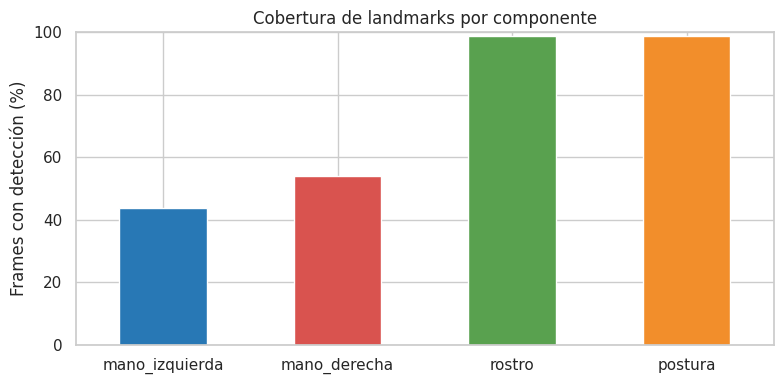

In [33]:
hands_raw = sequence["hands_raw"]
face_raw = sequence["face_raw"]
pose_raw = sequence["pose_raw"]
time_s = sequence["timestamp_s"]

hand_detected = np.isfinite(hands_raw[..., 0]).any(axis=2)  # (T, 2)
face_detected = np.isfinite(face_raw[..., 0]).any(axis=1)
pose_detected = np.isfinite(pose_raw[..., 0]).any(axis=1)

detection_summary = pd.Series({
    "mano_izquierda": 100 * hand_detected[:, 0].mean(),
    "mano_derecha": 100 * hand_detected[:, 1].mean(),
    "rostro": 100 * face_detected.mean(),
    "postura": 100 * pose_detected.mean(),
}, name="porcentaje_frames")

display(detection_summary.round(2).to_frame())

ax = detection_summary.plot.bar(figsize=(8, 4), color=["#2878B5", "#D9534F", "#59A14F", "#F28E2B"])
ax.set_ylim(0, 100)
ax.set_ylabel("Frames con detección (%)")
ax.set_title("Cobertura de landmarks por componente")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

if CREATE_ANNOTATED_VIDEO and ANNOTATED_VIDEO_PATH.exists():
    display(Video(str(ANNOTATED_VIDEO_PATH), embed=True, width=720))

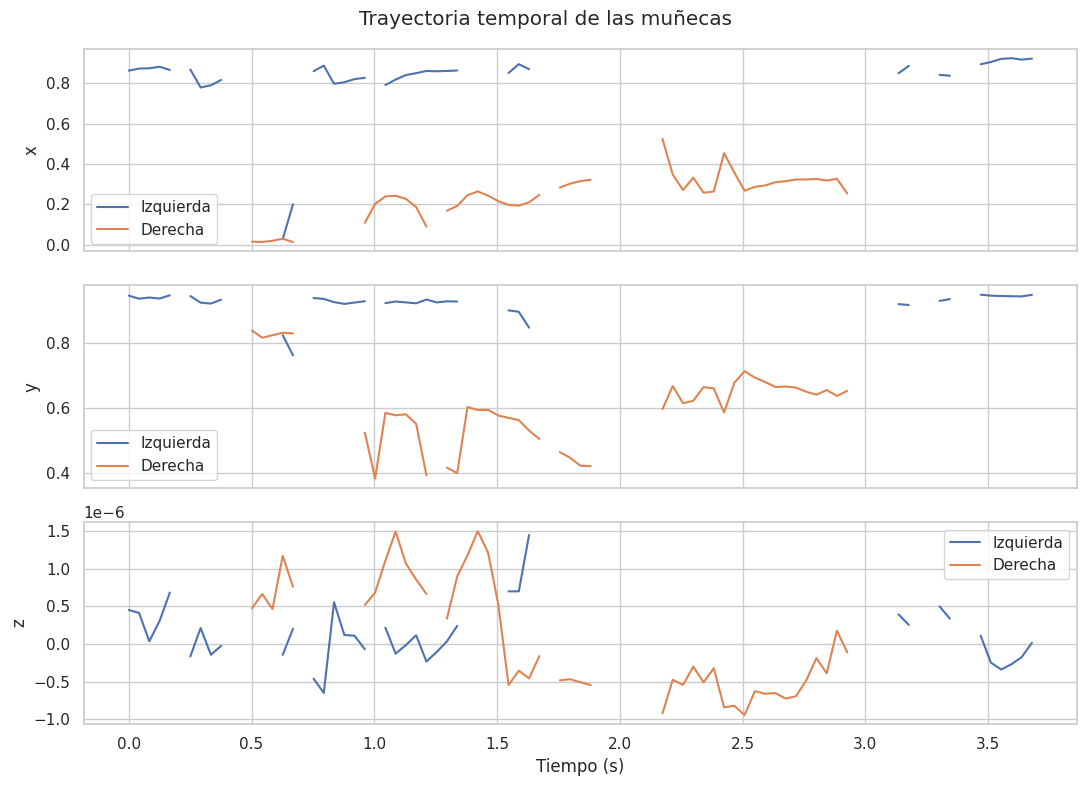

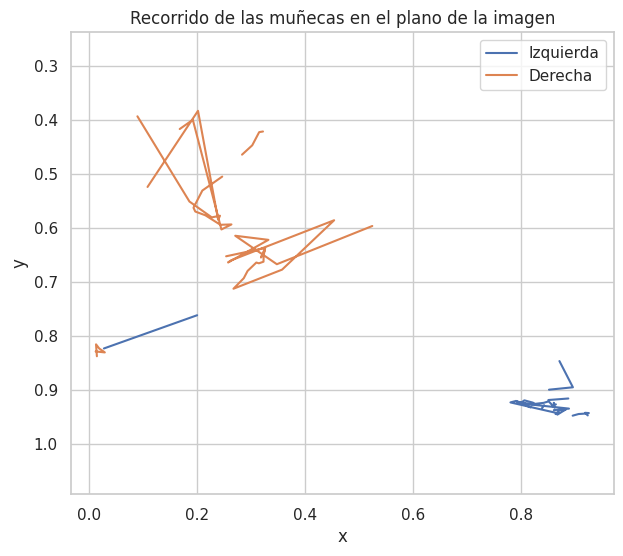

In [34]:
# Recorrido de la muñeca en la imagen.
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for axis_index, axis_name in enumerate(("x", "y", "z")):
    axes[axis_index].plot(time_s, hands_raw[:, 0, 0, axis_index], label="Izquierda")
    axes[axis_index].plot(time_s, hands_raw[:, 1, 0, axis_index], label="Derecha")
    axes[axis_index].set_ylabel(axis_name)
    axes[axis_index].legend(loc="best")
axes[-1].set_xlabel("Tiempo (s)")
fig.suptitle("Trayectoria temporal de las muñecas")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))
plt.plot(hands_raw[:, 0, 0, 0], hands_raw[:, 0, 0, 1], label="Izquierda")
plt.plot(hands_raw[:, 1, 0, 0], hands_raw[:, 1, 0, 1], label="Derecha")
plt.gca().invert_yaxis()
plt.xlabel("x")
plt.ylabel("y")
plt.title("Recorrido de las muñecas en el plano de la imagen")
plt.legend()
plt.axis("equal")
plt.show()

## 5. Normalización y tratamiento de faltantes

Se conservan los datos crudos y se crean representaciones complementarias:

- **Mano local:** se resta la muñeca y se divide entre la distancia muñeca–nudillo medio. Reduce el efecto de posición y tamaño, y representa la forma de la mano.
- **Movimiento corporal:** las manos se centran en el punto medio de los hombros y se dividen entre el ancho de hombros. Conserva el recorrido global respecto al cuerpo.
- **Rostro normalizado:** se centra en el punto facial de referencia y se escala con la distancia entre los extremos de los ojos.
- **Faltantes:** solo se interpolan huecos internos cortos. Se mantiene una máscara de detección para distinguir observaciones reales de valores interpolados.

Centrar las manos en la muñeca sin conservar otra representación eliminaría el desplazamiento de la seña. Por eso las coordenadas locales se usan para forma y las corporales para movimiento.

In [35]:
def normalize_hands_local(hands):
    result = np.full_like(hands, np.nan, dtype=np.float32)
    for t in range(hands.shape[0]):
        for h in range(2):
            hand = hands[t, h]
            if not np.isfinite(hand).all():
                continue
            wrist = hand[0]
            scale = np.linalg.norm(hand[9] - wrist)  # muñeca a MCP del dedo medio
            if np.isfinite(scale) and scale > 1e-8:
                result[t, h] = (hand - wrist) / scale
    return result


def normalize_hands_to_body(hands, pose):
    result = np.full_like(hands, np.nan, dtype=np.float32)
    for t in range(hands.shape[0]):
        left_shoulder = pose[t, 11, :3]
        right_shoulder = pose[t, 12, :3]
        if not (np.isfinite(left_shoulder).all() and np.isfinite(right_shoulder).all()):
            continue
        center = (left_shoulder + right_shoulder) / 2
        scale = np.linalg.norm((left_shoulder - right_shoulder)[:2])
        if not np.isfinite(scale) or scale <= 1e-8:
            continue
        for h, pose_wrist_index in enumerate((15, 16)):
            if np.isfinite(hands[t, h]).all():
                # Usa el centro y el ancho de los hombros como referencia.
                result[t, h, :, :2] = (hands[t, h, :, :2] - center[:2]) / scale
                wrist_depth = (pose[t, pose_wrist_index, 2] - center[2]) / scale
                result[t, h, :, 2] = wrist_depth + hands[t, h, :, 2] / scale
    return result


def normalize_face(face, indices):
    result = np.full_like(face, np.nan, dtype=np.float32)
    index_to_position = {int(index): position for position, index in enumerate(indices)}
    center_position = index_to_position[1]
    left_eye_position = index_to_position[33]
    right_eye_position = index_to_position[263]
    for t in range(face.shape[0]):
        points = face[t]
        if not np.isfinite(points).all():
            continue
        center = points[center_position]
        scale = np.linalg.norm((points[left_eye_position] - points[right_eye_position])[:2])
        if np.isfinite(scale) and scale > 1e-8:
            result[t] = (points - center) / scale
    return result


def interpolate_short_internal_gaps(array, max_gap=5):
    # Completa huecos internos de hasta max_gap frames.
    original_shape = array.shape
    flat = np.asarray(array, dtype=float).reshape(array.shape[0], -1)
    output = flat.copy()
    n = flat.shape[0]

    for column in range(flat.shape[1]):
        values = flat[:, column]
        missing = ~np.isfinite(values)
        start = 0
        while start < n:
            if not missing[start]:
                start += 1
                continue
            end = start
            while end < n and missing[end]:
                end += 1
            gap_length = end - start
            bounded = start > 0 and end < n
            if bounded and gap_length <= max_gap:
                output[start:end, column] = np.linspace(
                    values[start - 1], values[end], gap_length + 2
                )[1:-1]
            start = end
    return output.reshape(original_shape).astype(np.float32)


hands_local = normalize_hands_local(hands_raw)
hands_body = normalize_hands_to_body(hands_raw, pose_raw)
face_normalized = normalize_face(face_raw, FACE_INDICES)

hands_raw_interp = interpolate_short_internal_gaps(hands_raw, MAX_INTERPOLATION_GAP)
hands_local_interp = interpolate_short_internal_gaps(hands_local, MAX_INTERPOLATION_GAP)
hands_body_interp = interpolate_short_internal_gaps(hands_body, MAX_INTERPOLATION_GAP)
face_normalized_interp = interpolate_short_internal_gaps(face_normalized, MAX_INTERPOLATION_GAP)
pose_interp = interpolate_short_internal_gaps(pose_raw, MAX_INTERPOLATION_GAP)

print("Datos crudos conservados:", hands_raw.shape)
print("Representación local:", hands_local.shape)
print("Representación respecto al cuerpo:", hands_body.shape)

Datos crudos conservados: (89, 2, 21, 3)
Representación local: (89, 2, 21, 3)
Representación respecto al cuerpo: (89, 2, 21, 3)


## 6. Exportación de secuencias

El archivo NPZ conserva eficientemente las matrices temporales. Los CSV se exportan en formato largo: cada fila identifica video, participante, seña, frame, lado y landmark. Así las dos manos siguen perteneciendo al mismo video y pueden reconstruirse sin ambigüedad.

In [36]:
np.savez_compressed(
    NPZ_PATH,
    hands_raw=hands_raw,
    hands_local=hands_local,
    hands_body=hands_body,
    hands_raw_interpolated=hands_raw_interp,
    hands_local_interpolated=hands_local_interp,
    hands_body_interpolated=hands_body_interp,
    hand_detected=hand_detected,
    face_raw=face_raw,
    face_indices=FACE_INDICES,
    face_normalized=face_normalized,
    face_normalized_interpolated=face_normalized_interp,
    pose_raw=pose_raw,
    pose_interpolated=pose_interp,
    source_frame=sequence["source_frame"],
    timestamp_s=time_s,
    fps_original=np.array([sequence["fps_original"]]),
    fps_effective=np.array([sequence["fps_effective"]]),
    sign_label=np.array([SIGN_LABEL]),
    participant_id=np.array([PARTICIPANT_ID]),
    video_id=np.array([VIDEO_ID]),
)


def hands_to_long_dataframe():
    rows = []
    for t in range(hands_raw.shape[0]):
        for hand_index, hand_name in enumerate(HAND_NAMES):
            for landmark in range(21):
                rows.append({
                    "video_id": VIDEO_ID,
                    "participant_id": PARTICIPANT_ID,
                    "sign_label": SIGN_LABEL,
                    "source_frame": int(sequence["source_frame"][t]),
                    "timestamp_s": float(time_s[t]),
                    "hand": hand_name,
                    "landmark": landmark,
                    "detected": bool(hand_detected[t, hand_index]),
                    "x_raw": hands_raw[t, hand_index, landmark, 0],
                    "y_raw": hands_raw[t, hand_index, landmark, 1],
                    "z_raw": hands_raw[t, hand_index, landmark, 2],
                    "x_local": hands_local[t, hand_index, landmark, 0],
                    "y_local": hands_local[t, hand_index, landmark, 1],
                    "z_local": hands_local[t, hand_index, landmark, 2],
                    "x_body": hands_body[t, hand_index, landmark, 0],
                    "y_body": hands_body[t, hand_index, landmark, 1],
                    "z_body": hands_body[t, hand_index, landmark, 2],
                })
    return pd.DataFrame(rows)


def component_to_long_dataframe(values, component, landmark_ids, coordinate_names):
    rows = []
    for t in range(values.shape[0]):
        for position, landmark_id in enumerate(landmark_ids):
            row = {
                "video_id": VIDEO_ID,
                "participant_id": PARTICIPANT_ID,
                "sign_label": SIGN_LABEL,
                "source_frame": int(sequence["source_frame"][t]),
                "timestamp_s": float(time_s[t]),
                "component": component,
                "landmark": int(landmark_id),
            }
            row.update({name: values[t, position, i] for i, name in enumerate(coordinate_names)})
            rows.append(row)
    return pd.DataFrame(rows)


hands_long = hands_to_long_dataframe()
face_long = component_to_long_dataframe(
    face_raw, "face", FACE_INDICES, ("x", "y", "z")
)
pose_long = component_to_long_dataframe(
    pose_raw, "pose", np.arange(33), ("x", "y", "z", "visibility")
)

hands_long.to_csv(HANDS_CSV_PATH, index=False)
face_long.to_csv(FACE_CSV_PATH, index=False)
pose_long.to_csv(POSE_CSV_PATH, index=False)

print("NPZ:", NPZ_PATH)
print("CSV manos:", HANDS_CSV_PATH, hands_long.shape)
print("CSV rostro:", FACE_CSV_PATH, face_long.shape)
print("CSV postura:", POSE_CSV_PATH, pose_long.shape)
display(hands_long.head())

NPZ: /content/output_avance2/Necesitar_Hugo_01_secuencia.npz
CSV manos: /content/output_avance2/Necesitar_Hugo_01_landmarks_manos.csv (3738, 17)
CSV rostro: /content/output_avance2/Necesitar_Hugo_01_landmarks_rostro.csv (2225, 10)
CSV postura: /content/output_avance2/Necesitar_Hugo_01_landmarks_postura.csv (2937, 11)


,video_id,participant_id,sign_label,source_frame,timestamp_s,hand,landmark,detected,x_raw,y_raw,z_raw,x_local,y_local,z_local,x_body,y_body,z_body
0,Necesitar_Hugo_01,Hugo,Necesitar,0,0.0,left,0,True,0.863960,0.944120,4.534945e-07,0.000000,0.000000,0.000000,0.372521,0.566097,-2.659610
1,Necesitar_Hugo_01,Hugo,Necesitar,0,0.0,left,1,True,0.755329,0.923383,-5.574529e-02,-0.462038,-0.088200,-0.237102,0.231114,0.539103,-2.732175
2,Necesitar_Hugo_01,Hugo,Necesitar,0,0.0,left,2,True,0.633491,0.921383,-6.355655e-02,-0.980247,-0.096708,-0.270325,0.072516,0.536499,-2.742343
3,Necesitar_Hugo_01,Hugo,Necesitar,0,0.0,left,3,True,0.523992,0.938839,-5.704334e-02,-1.445977,-0.022459,-0.242623,-0.070021,0.559223,-2.733865
4,Necesitar_Hugo_01,Hugo,Necesitar,0,0.0,left,4,True,0.434047,0.960385,-4.702250e-02,-1.828537,0.069181,-0.200001,-0.187104,0.587270,-2.720820


## 7. Construcción de nuevas características

Se resume cada video en una sola fila. Las características se eligieron por su relación con una seña dinámica:

- **Cobertura:** proporción de frames detectados por mano.
- **Movimiento:** recorrido, desplazamiento, velocidad, aceleración y rango de la muñeca.
- **Configuración manual:** apertura, distancia pulgar–índice y flexión de los dedos.
- **Coordinación bimanual:** distancia y cambio relativo entre muñecas.
- **Componentes no manuales:** apertura de boca y ángulos de los codos.

Los identificadores (`video_id`, `participant_id`) se conservan como metadatos, pero no deben usarse como predictores porque provocarían fuga de información. `sign_label` es la variable objetivo.

In [37]:
def finite_values(values):
    values = np.asarray(values, dtype=float).ravel()
    return values[np.isfinite(values)]


def add_stats(features, prefix, values, statistics=("mean", "std", "min", "max")):
    values = finite_values(values)
    for statistic in statistics:
        key = f"{prefix}_{statistic}"
        if values.size == 0:
            features[key] = np.nan
        elif statistic == "mean":
            features[key] = float(values.mean())
        elif statistic == "std":
            features[key] = float(values.std(ddof=0))
        elif statistic == "min":
            features[key] = float(values.min())
        elif statistic == "max":
            features[key] = float(values.max())


def vector_angle(a, b, c):
    # Ángulo formado por A-B-C.
    ba = a - b
    bc = c - b
    denominator = np.linalg.norm(ba, axis=-1) * np.linalg.norm(bc, axis=-1)
    cosine = np.divide(
        np.sum(ba * bc, axis=-1),
        denominator,
        out=np.full_like(denominator, np.nan, dtype=float),
        where=denominator > 1e-8,
    )
    return np.degrees(np.arccos(np.clip(cosine, -1, 1)))


def motion_features(trajectory, fps, features, prefix):
    trajectory = np.asarray(trajectory, dtype=float)
    valid = np.isfinite(trajectory).all(axis=1)
    valid_points = trajectory[valid]
    if valid_points.shape[0] >= 2:
        features[f"{prefix}_net_displacement"] = float(
            np.linalg.norm(valid_points[-1] - valid_points[0])
        )
    else:
        features[f"{prefix}_net_displacement"] = np.nan

    consecutive = valid[:-1] & valid[1:]
    steps = np.linalg.norm(np.diff(trajectory, axis=0), axis=1)
    valid_steps = steps[consecutive]
    features[f"{prefix}_path_length"] = (
        float(valid_steps.sum()) if valid_steps.size else np.nan
    )
    speeds = valid_steps * fps
    add_stats(features, f"{prefix}_speed", speeds, ("mean", "std", "max"))
    if speeds.size >= 2:
        accelerations = np.abs(np.diff(speeds)) * fps
    else:
        accelerations = np.array([])
    add_stats(features, f"{prefix}_acceleration", accelerations, ("mean", "max"))

    for coordinate, name in enumerate(("x", "y", "z")):
        coordinate_values = finite_values(trajectory[:, coordinate])
        features[f"{prefix}_{name}_range"] = (
            float(np.ptp(coordinate_values)) if coordinate_values.size else np.nan
        )


def choose_global_hand_coordinates():
    body_coverage = np.isfinite(hands_body_interp[..., 0]).any(axis=(1, 2)).mean()
    if body_coverage >= 0.50:
        return hands_body_interp, "body"
    return hands_raw_interp, "image"


def build_video_features():
    features = {
        "video_id": VIDEO_ID,
        "participant_id": PARTICIPANT_ID,
        "sign_label": SIGN_LABEL,
        "repetition_id": REPETITION_ID,
        "n_frames": hands_raw.shape[0],
        "duration_s": float(time_s[-1] - time_s[0]) if len(time_s) > 1 else 0.0,
        "fps_effective": float(sequence["fps_effective"]),
    }

    global_hands, reference = choose_global_hand_coordinates()
    features["movement_reference"] = reference

    fingertip_ids = np.array([4, 8, 12, 16, 20])
    finger_joints = [(5, 6, 7), (9, 10, 11), (13, 14, 15), (17, 18, 19)]

    for h, hand_name in enumerate(HAND_NAMES):
        features[f"{hand_name}_detection_ratio"] = float(hand_detected[:, h].mean())
        motion_features(
            global_hands[:, h, 0, :],
            sequence["fps_effective"],
            features,
            f"{hand_name}_wrist",
        )

        local = hands_local_interp[:, h]
        openness = np.nanmean(np.linalg.norm(local[:, fingertip_ids] - local[:, [0]], axis=2), axis=1)
        pinch = np.linalg.norm(local[:, 4] - local[:, 8], axis=1)
        flexion = np.column_stack([
            vector_angle(local[:, a], local[:, b], local[:, c])
            for a, b, c in finger_joints
        ])
        add_stats(features, f"{hand_name}_openness", openness, ("mean", "std", "min", "max"))
        add_stats(features, f"{hand_name}_pinch", pinch, ("mean", "std", "min"))
        add_stats(features, f"{hand_name}_finger_flexion", flexion, ("mean", "std"))

    left_wrist = global_hands[:, 0, 0]
    right_wrist = global_hands[:, 1, 0]
    inter_wrist = np.linalg.norm(left_wrist - right_wrist, axis=1)
    add_stats(features, "inter_wrist_distance", inter_wrist)
    if np.isfinite(inter_wrist).sum() >= 2:
        valid_inter = inter_wrist[np.isfinite(inter_wrist)]
        features["inter_wrist_distance_change"] = float(np.abs(np.diff(valid_inter)).sum())
    else:
        features["inter_wrist_distance_change"] = np.nan

    face_map = {int(index): position for position, index in enumerate(FACE_INDICES)}
    mouth_height = np.linalg.norm(
        face_normalized_interp[:, face_map[13]] - face_normalized_interp[:, face_map[14]],
        axis=1,
    )
    mouth_width = np.linalg.norm(
        face_normalized_interp[:, face_map[61]] - face_normalized_interp[:, face_map[291]],
        axis=1,
    )
    mouth_open_ratio = np.divide(
        mouth_height,
        mouth_width,
        out=np.full_like(mouth_height, np.nan),
        where=mouth_width > 1e-8,
    )
    add_stats(features, "mouth_open_ratio", mouth_open_ratio, ("mean", "std", "max"))

    for side, shoulder, elbow, wrist in (
        ("left", 11, 13, 15),
        ("right", 12, 14, 16),
    ):
        elbow_angle = vector_angle(
            pose_interp[:, shoulder, :3],
            pose_interp[:, elbow, :3],
            pose_interp[:, wrist, :3],
        )
        add_stats(features, f"{side}_elbow_angle", elbow_angle, ("mean", "std", "min", "max"))

    features["face_detection_ratio"] = float(face_detected.mean())
    features["pose_detection_ratio"] = float(pose_detected.mean())
    features["both_hands_detection_ratio"] = float(hand_detected.all(axis=1).mean())
    return pd.DataFrame([features])


video_features = build_video_features()
video_features.to_csv(FEATURES_CSV_PATH, index=False)

if MASTER_FEATURES_PATH.exists():
    master_features = pd.read_csv(MASTER_FEATURES_PATH)
    if "video_id" in master_features.columns:
        master_features = master_features[master_features["video_id"] != VIDEO_ID]
    master_features = pd.concat([master_features, video_features], ignore_index=True)
else:
    master_features = video_features.copy()

master_features.to_csv(MASTER_FEATURES_PATH, index=False)
print("Características de este video:", FEATURES_CSV_PATH)
print("Dataset acumulado:", MASTER_FEATURES_PATH)
print("Videos acumulados:", len(master_features))
display(video_features.T)

Características de este video: /content/output_avance2/Necesitar_Hugo_01_caracteristicas.csv
Dataset acumulado: /content/output_avance2/dataset_caracteristicas.csv
Videos acumulados: 3


,0
video_id,Necesitar_Hugo_01
participant_id,Hugo
sign_label,Necesitar
repetition_id,01
n_frames,89
...,...
right_elbow_angle_min,91.838868
right_elbow_angle_max,157.871062
face_detection_ratio,0.988764
pose_detection_ratio,0.988764


## 8. Preparación y selección de características

Esta parte trabaja con `dataset_caracteristicas.csv`, donde cada fila corresponde a un video. Antes de aplicar PCA se realiza lo siguiente:

1. Se descartan columnas con más de 40 % de datos faltantes.
2. Los faltantes restantes se completan con la mediana.
3. Se eliminan variables con varianza casi nula.
4. Se eliminan variables con correlación absoluta mayor a 0.95.
5. Se aplica Yeo-Johnson únicamente cuando hay suficientes observaciones y la asimetría es alta.
6. Las variables finales se estandarizan para que sus escalas sean comparables.

Los ajustes se calculan con los datos de entrenamiento. Cuando hay suficientes participantes, la separación se realiza por persona; de lo contrario, se usa una separación provisional por video.


In [38]:
METADATA_COLUMNS = {
    "video_id", "participant_id", "sign_label", "repetition_id",
    "movement_reference"
}


def split_without_identity_leakage(data):
    y = data["sign_label"].astype(str)
    participants = data["participant_id"].astype(str)

    if participants.nunique() >= 3:
        splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
        train_index, test_index = next(splitter.split(data, y, groups=participants))
        method = "separación por participante"
    else:
        class_counts = y.value_counts()
        if class_counts.min() < 2:
            raise ValueError(
                "Se requieren al menos dos videos por seña para separar entrenamiento y prueba."
            )
        train_index, test_index = train_test_split(
            np.arange(len(data)),
            test_size=0.25,
            random_state=42,
            stratify=y,
        )
        method = "separación estratificada por video"
    return train_index, test_index, method


def remove_high_correlation(frame, threshold=0.95):
    correlation = frame.corr().abs()
    upper = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))
    to_drop = [column for column in upper.columns if (upper[column] > threshold).any()]
    return to_drop, correlation


preparation_results = None
base_artifacts = None
X_train_scaled = None
X_test_scaled = None

data = pd.read_csv(MASTER_FEATURES_PATH)
class_counts = data["sign_label"].value_counts()

print("Videos:", len(data))
print("Señas:", data["sign_label"].nunique())
display(class_counts.rename("videos").to_frame())

enough_data = (
    len(data) >= 8
    and data["sign_label"].nunique() >= 2
    and class_counts.min() >= 2
)

if not enough_data:
    print(
        "Preparación estadística pendiente. Se necesitan al menos ocho videos, "
        "dos clases y dos videos por clase."
    )
else:
    train_index, test_index, split_method = split_without_identity_leakage(data)
    train = data.iloc[train_index].copy()
    test = data.iloc[test_index].copy()

    numeric_columns = [
        column for column in data.select_dtypes(include=np.number).columns
        if column not in METADATA_COLUMNS
    ]

    missing_rate = train[numeric_columns].isna().mean()
    retained_for_missingness = missing_rate[missing_rate <= 0.40].index.tolist()
    dropped_missingness = missing_rate[missing_rate > 0.40].index.tolist()

    X_train_df = train[retained_for_missingness].replace([np.inf, -np.inf], np.nan)
    X_test_df = test[retained_for_missingness].replace([np.inf, -np.inf], np.nan)

    imputer = SimpleImputer(strategy="median")
    X_train_imputed = pd.DataFrame(
        imputer.fit_transform(X_train_df),
        columns=retained_for_missingness,
        index=X_train_df.index,
    )
    X_test_imputed = pd.DataFrame(
        imputer.transform(X_test_df),
        columns=retained_for_missingness,
        index=X_test_df.index,
    )

    variance_filter = VarianceThreshold(threshold=1e-6)
    X_train_variance = variance_filter.fit_transform(X_train_imputed)
    variance_columns = X_train_imputed.columns[variance_filter.get_support()].tolist()
    X_train_variance = pd.DataFrame(
        X_train_variance, columns=variance_columns, index=X_train_imputed.index
    )
    X_test_variance = pd.DataFrame(
        variance_filter.transform(X_test_imputed),
        columns=variance_columns,
        index=X_test_imputed.index,
    )

    correlated_to_drop, correlation_matrix = remove_high_correlation(
        X_train_variance, threshold=0.95
    )
    correlation_columns = [c for c in variance_columns if c not in correlated_to_drop]
    X_train_filtered = X_train_variance[correlation_columns].copy()
    X_test_filtered = X_test_variance[correlation_columns].copy()

    skewed_columns = []
    power_transformer = None
    if len(X_train_filtered) >= 20:
        skewness = X_train_filtered.skew().abs()
        skewed_columns = skewness[skewness > 1.0].index.tolist()
        if skewed_columns:
            power_transformer = PowerTransformer(method="yeo-johnson", standardize=False)
            X_train_filtered.loc[:, skewed_columns] = power_transformer.fit_transform(
                X_train_filtered[skewed_columns]
            )
            X_test_filtered.loc[:, skewed_columns] = power_transformer.transform(
                X_test_filtered[skewed_columns]
            )

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_filtered)
    X_test_scaled = scaler.transform(X_test_filtered)

    preparation_results = {
        "tipo_de_separacion": split_method,
        "videos_entrenamiento": len(train),
        "videos_prueba": len(test),
        "caracteristicas_iniciales": len(numeric_columns),
        "eliminadas_por_faltantes": dropped_missingness,
        "despues_de_faltantes": len(retained_for_missingness),
        "despues_de_varianza": len(variance_columns),
        "eliminadas_por_correlacion": correlated_to_drop,
        "despues_de_correlacion": len(correlation_columns),
        "transformadas_con_yeo_johnson": skewed_columns,
    }

    base_artifacts = {
        "feature_columns": numeric_columns,
        "retained_for_missingness": retained_for_missingness,
        "imputer": imputer,
        "variance_filter": variance_filter,
        "correlation_columns": correlation_columns,
        "power_transformer": power_transformer,
        "skewed_columns": skewed_columns,
        "scaler": scaler,
    }

    display(pd.Series(preparation_results).to_frame("resultado"))


Videos: 3
Señas: 3


,videos
sign_label,
Trabajo,1
Amigo,1
Necesitar,1


Preparación estadística pendiente. Se necesitan al menos ocho videos, dos clases y dos videos por clase.


## 9. Análisis de componentes principales (PCA)

PCA se utiliza como técnica de extracción para representar las variables correlacionadas con un número menor de componentes. Se aplica después de la imputación, los filtros de varianza y correlación, y la estandarización.

Se conserva al menos 95 % de la varianza. El ajuste se hace únicamente con entrenamiento y después se transforma el conjunto de prueba con el mismo modelo.


In [39]:
pca = None
pca_results = None
X_train_pca = None
X_test_pca = None

if preparation_results is None:
    print("PCA pendiente. Primero se necesitan más videos en el dataset acumulado.")
else:
    max_components = min(X_train_scaled.shape[0], X_train_scaled.shape[1])

    if max_components < 2:
        print("PCA pendiente. No hay suficientes observaciones para calcular componentes.")
    else:
        pca = PCA(n_components=0.95, svd_solver="full")
        X_train_pca = pca.fit_transform(X_train_scaled)
        X_test_pca = pca.transform(X_test_scaled)

        cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
        pca_results = {
            "componentes": int(pca.n_components_),
            "varianza_explicada": float(pca.explained_variance_ratio_.sum()),
        }

        display(pd.Series(pca_results).to_frame("resultado"))

        plt.figure(figsize=(8, 4))
        plt.plot(
            np.arange(1, len(cumulative_variance) + 1),
            cumulative_variance,
            marker="o",
        )
        plt.axhline(0.95, color="red", linestyle="--", label="95 %")
        plt.ylim(0, 1.05)
        plt.xlabel("Número de componentes")
        plt.ylabel("Varianza acumulada")
        plt.title("Varianza explicada por PCA")
        plt.legend()
        plt.tight_layout()
        plt.show()

        artifacts = dict(base_artifacts)
        artifacts["pca"] = pca
        joblib.dump(artifacts, OUTPUT_DIR / "preprocesamiento_avance2.joblib")


PCA pendiente. Primero se necesitan más videos en el dataset acumulado.


## 10. ANOVA (pendiente)

ANOVA se deja pendiente porque todavía no hay suficientes repeticiones de cada seña para comparar la variación dentro y entre las clases. Aplicarlo con una sola observación por seña produciría resultados que no se pueden interpretar de manera confiable.

Cuando el dataset tenga varias repeticiones por clase, este apartado podrá utilizarse para identificar las características con mayores diferencias entre las señas.


## 11. Conclusiones de la preparación de datos

La libreta permite pasar de un video a una secuencia de landmarks y después a una fila de características. Se conserva la información de ambas manos, el rostro y la postura, junto con los datos necesarios para identificar el video, la seña y el participante.

La normalización local ayuda a comparar la forma de la mano sin depender tanto de su tamaño o posición en la imagen. La referencia corporal conserva el desplazamiento de la seña respecto a los hombros. También se mantienen los valores faltantes cuando MediaPipe no detecta una mano y únicamente se completan huecos cortos entre detecciones válidas.

Con los videos acumulados todavía no es posible interpretar PCA ni ANOVA como resultados finales. PCA quedó separado y listo para ejecutarse cuando se reúna el mínimo de observaciones; ANOVA se mantiene pendiente hasta tener varias repeticiones por seña. En términos de CRISP-ML(Q), la preparación de los datos sigue abierta: falta ampliar el conjunto de videos, mejorar la detección de las manos y volver a ejecutar los filtros y PCA antes de entrenar un clasificador.


In [40]:
summary = {
    "videos_acumulados": int(len(data)),
    "senas": int(data["sign_label"].nunique()),
    "participantes": int(data["participant_id"].nunique()),
    "preparacion_estadistica_ejecutada": preparation_results is not None,
    "pca_ejecutado": pca_results is not None,
    "anova_ejecutado": False,
    "deteccion_mano_izquierda_pct_video_actual": round(float(detection_summary["mano_izquierda"]), 2),
    "deteccion_mano_derecha_pct_video_actual": round(float(detection_summary["mano_derecha"]), 2),
    "deteccion_rostro_pct_video_actual": round(float(detection_summary["rostro"]), 2),
    "deteccion_postura_pct_video_actual": round(float(detection_summary["postura"]), 2),
}

if preparation_results is not None:
    summary.update({
        "caracteristicas_iniciales": preparation_results["caracteristicas_iniciales"],
        "caracteristicas_despues_de_varianza": preparation_results["despues_de_varianza"],
        "caracteristicas_despues_de_correlacion": preparation_results["despues_de_correlacion"],
    })

if pca_results is not None:
    summary.update({
        "componentes_pca": pca_results["componentes"],
        "varianza_pca": pca_results["varianza_explicada"],
    })

with open(OUTPUT_DIR / "resumen_avance2.json", "w", encoding="utf-8") as file:
    json.dump(summary, file, ensure_ascii=False, indent=2)

display(pd.Series(summary).to_frame("valor"))
print("Archivos generados:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print("-", path.name)


,valor
videos_acumulados,3
senas,3
participantes,1
preparacion_estadistica_ejecutada,False
pca_ejecutado,False
anova_ejecutado,False
deteccion_mano_izquierda_pct_video_actual,43.82
deteccion_mano_derecha_pct_video_actual,53.93
deteccion_rostro_pct_video_actual,98.88
deteccion_postura_pct_video_actual,98.88


Archivos generados:
- Amigo_Hugo_01_anotado.mp4
- Amigo_Hugo_01_caracteristicas.csv
- Amigo_Hugo_01_landmarks_manos.csv
- Amigo_Hugo_01_landmarks_postura.csv
- Amigo_Hugo_01_landmarks_rostro.csv
- Amigo_Hugo_01_secuencia.npz
- Necesitar_Hugo_01_anotado.mp4
- Necesitar_Hugo_01_caracteristicas.csv
- Necesitar_Hugo_01_landmarks_manos.csv
- Necesitar_Hugo_01_landmarks_postura.csv
- Necesitar_Hugo_01_landmarks_rostro.csv
- Necesitar_Hugo_01_secuencia.npz
- Trabajo_Hugo_01_anotado.mp4
- Trabajo_Hugo_01_caracteristicas.csv
- Trabajo_Hugo_01_landmarks_manos.csv
- Trabajo_Hugo_01_landmarks_postura.csv
- Trabajo_Hugo_01_landmarks_rostro.csv
- Trabajo_Hugo_01_secuencia.npz
- dataset_caracteristicas.csv
- resumen_avance2.json


## 12. Uso con los siguientes videos

1. Conservar `dataset_caracteristicas.csv` antes de cerrar la sesión de Colab.
2. En una sesión nueva, subir el CSV dentro de `output_avance2`.
3. Subir el siguiente video y cambiar `VIDEO_FILENAME`.
4. Ejecutar nuevamente desde la configuración hasta el resumen.
5. Antes de entregar, ejecutar toda la libreta de principio a fin y comprobar que no haya errores.


## 13. Descargas

### Descargar el dataset acumulado


In [41]:
from google.colab import files

files.download(
    "/content/output_avance2/dataset_caracteristicas.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Descargar todos los resultados


In [42]:
!zip -r /content/output_avance2.zip /content/output_avance2

from google.colab import files
files.download("/content/output_avance2.zip")

updating: content/output_avance2/ (stored 0%)
updating: content/output_avance2/Trabajo_Hugo_01_landmarks_manos.csv (deflated 78%)
updating: content/output_avance2/dataset_caracteristicas.csv (deflated 54%)
updating: content/output_avance2/Trabajo_Hugo_01_caracteristicas.csv (deflated 59%)
updating: content/output_avance2/Trabajo_Hugo_01_secuencia.npz (deflated 9%)
updating: content/output_avance2/Trabajo_Hugo_01_landmarks_postura.csv (deflated 76%)
updating: content/output_avance2/resumen_avance2.json (deflated 55%)
updating: content/output_avance2/Trabajo_Hugo_01_anotado.mp4 (deflated 1%)
updating: content/output_avance2/Trabajo_Hugo_01_landmarks_rostro.csv (deflated 79%)
updating: content/output_avance2/Amigo_Hugo_01_anotado.mp4 (deflated 1%)
updating: content/output_avance2/Amigo_Hugo_01_landmarks_postura.csv (deflated 75%)
updating: content/output_avance2/Amigo_Hugo_01_landmarks_manos.csv (deflated 76%)
updating: content/output_avance2/Amigo_Hugo_01_secuencia.npz (deflated 9%)
upda

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>